# Real Bayer colour reconstruction: observations to spatial camera RGB

This review actively reconstructs the complete2128×2840 real exposure with cleaned local mathematics. There is no independent physical RGB truth. Original-reference agreement and observed-sample consistency are distinct from missing-channel accuracy. Three2D colour fields, not a scalar calibration, are the inverse target.

The black-corrected model is $y=\sum_c M_c x_c+\eta$: $y$ is normalized sensor intensity, $M_c$ is the known one-hot colour mask, $x_c$ the unknown colour field and $\eta$ sensor/model error. The native sensor is10bit with black31ADU and white1023ADU; top-left RGGB determines masks. The direct5×5 Malvar filter combines same-colour interpolation and cross-channel curvature correction. Reflective boundaries and signed output follow the reference. There is no iterative optimization or invented convergence plot.

In [1]:
from pathlib import Path
import os,time,json,hashlib,sys
import numpy as np
import matplotlib.pyplot as plt
cwd=Path.cwd()
task=next((p for p in [cwd,*cwd.parents] if (p/'data/raw_data.npz').exists()),cwd/'tasks/bayer_raw_colour_reconstruction')
os.chdir(task)
sys.path.insert(0,str(task))
from src.preprocessing import load_observations,normalize_mosaic
from src.physics_model import sample_rgb
from src.solvers import reconstruct,bilinear_comparison
from src.visualization import compute_metrics,render_figures
start=time.perf_counter()
raw,black,wb=load_observations()
mosaic=normalize_mosaic(raw,black)
t=time.perf_counter();fresh=reconstruct(mosaic);fresh_seconds=time.perf_counter()-t
t=time.perf_counter();bilinear=bilinear_comparison(mosaic);bilinear_seconds=time.perf_counter()-t
with np.load('evaluation/baseline_reference.npz',allow_pickle=False) as z: upstream=z['reconstruction'][0]
with np.load('notebooks/reference_outputs/upstream_bilinear.npz',allow_pickle=False) as z: upstream_bilinear=z['reconstruction'][0]
malvar_parity=compute_metrics(fresh,upstream)
bilinear_parity=compute_metrics(bilinear,upstream_bilinear)
consistency=float(np.max(np.abs(sample_rgb(fresh)-mosaic)))
assert np.max(np.abs(fresh-upstream))<1e-13
assert np.max(np.abs(bilinear-upstream_bilinear))<1e-13
assert consistency<=1e-12
measurements={'fresh_malvar_vs_original':malvar_parity,'fresh_bilinear_vs_original':bilinear_parity,'fresh_malvar_seconds':fresh_seconds,'fresh_bilinear_seconds':bilinear_seconds,'sample_consistency_max_abs':consistency,'shape':list(fresh.shape),'negative_output_fraction':float(np.mean(fresh<0)),'above_white_output_fraction':float(np.mean(fresh>1)),'reference_type':'independently run original method, not physical RGB truth'}
print(json.dumps(measurements,indent=2))
del upstream_bilinear

{
  "fresh_malvar_vs_original": {
    "ncc": 0.9999999999999999,
    "nrmse": 0.0
  },
  "fresh_bilinear_vs_original": {
    "ncc": 1.0,
    "nrmse": 0.0
  },
  "fresh_malvar_seconds": 0.27235490000020945,
  "fresh_bilinear_seconds": 0.14273880000109784,
  "sample_consistency_max_abs": 0.0,
  "shape": [
    2128,
    2840,
    3
  ],
  "negative_output_fraction": 0.00022249726428747927,
  "above_white_output_fraction": 0.0,
  "reference_type": "independently run original method, not physical RGB truth"
}


## Actual comparisons and diagnostic experiments

The first group shows the full field using stride4 for display only. The next group uses native256×256 plant/soil detail windows. All RGB displays share white balance, exposure and gamma; signed numeric images remain unchanged. The profiles overlay only genuinely measured channels; the row has no blue measurements, so no blue observation is invented. Method differences are not errors to truth. The fourth group evaluates prescribed filter coefficients and unit impulses as mathematical diagnostics, not as additional measured scenes. These reveal signed ringing and the spread of sensor defects. No algorithm is replaced by an archived image: both Malvar and bilinear were freshly computed above.

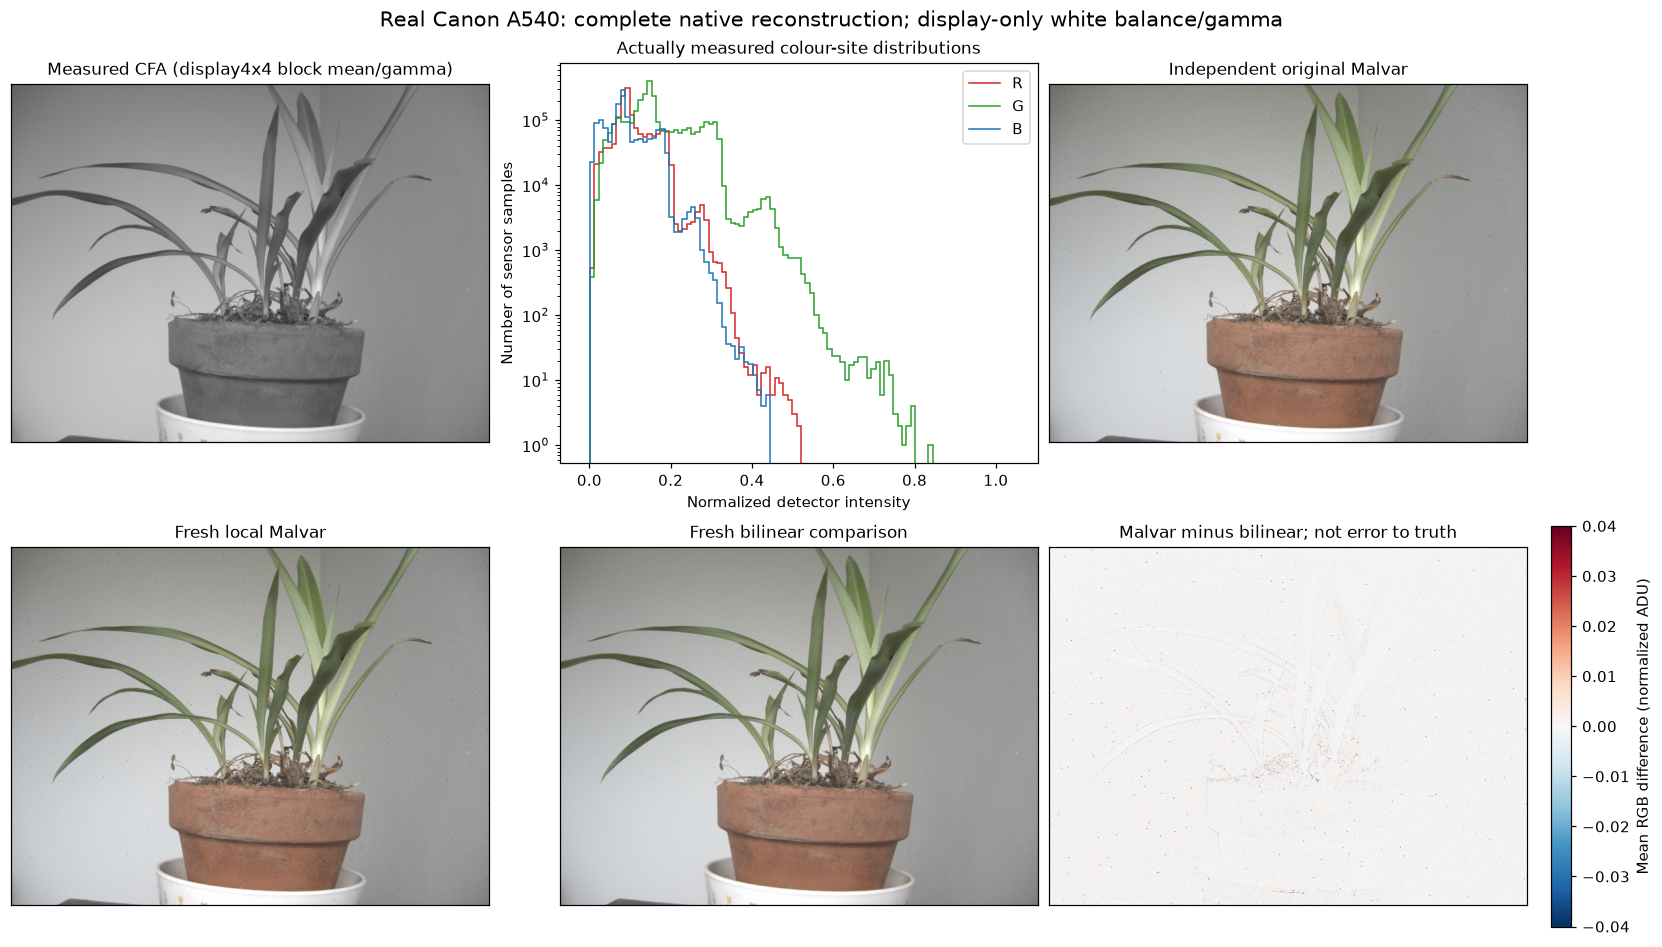

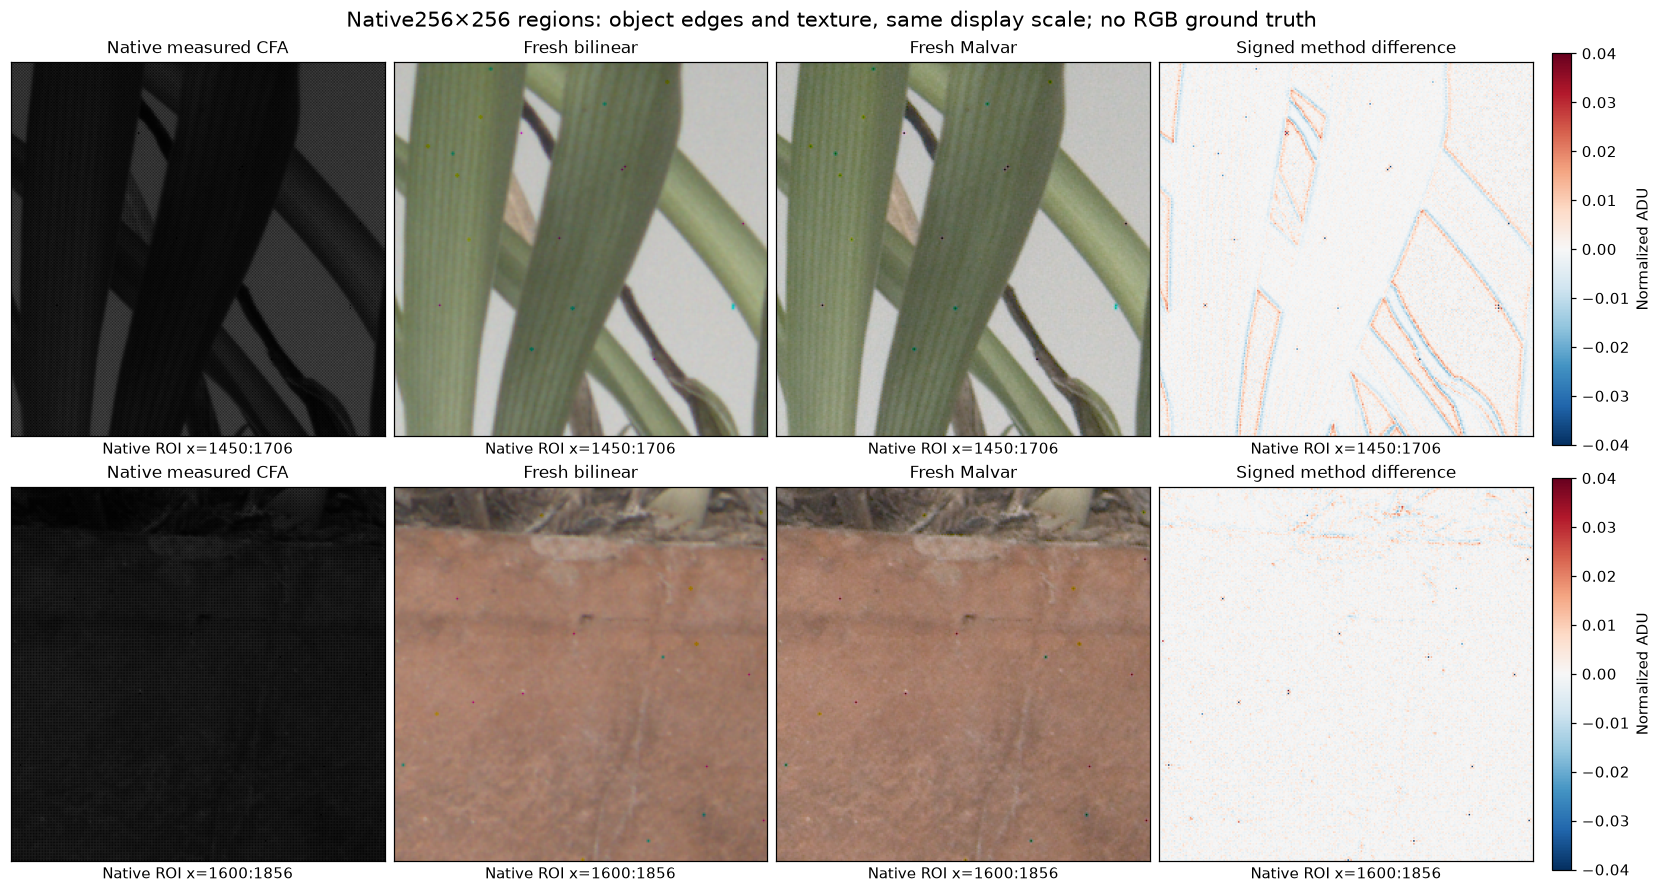

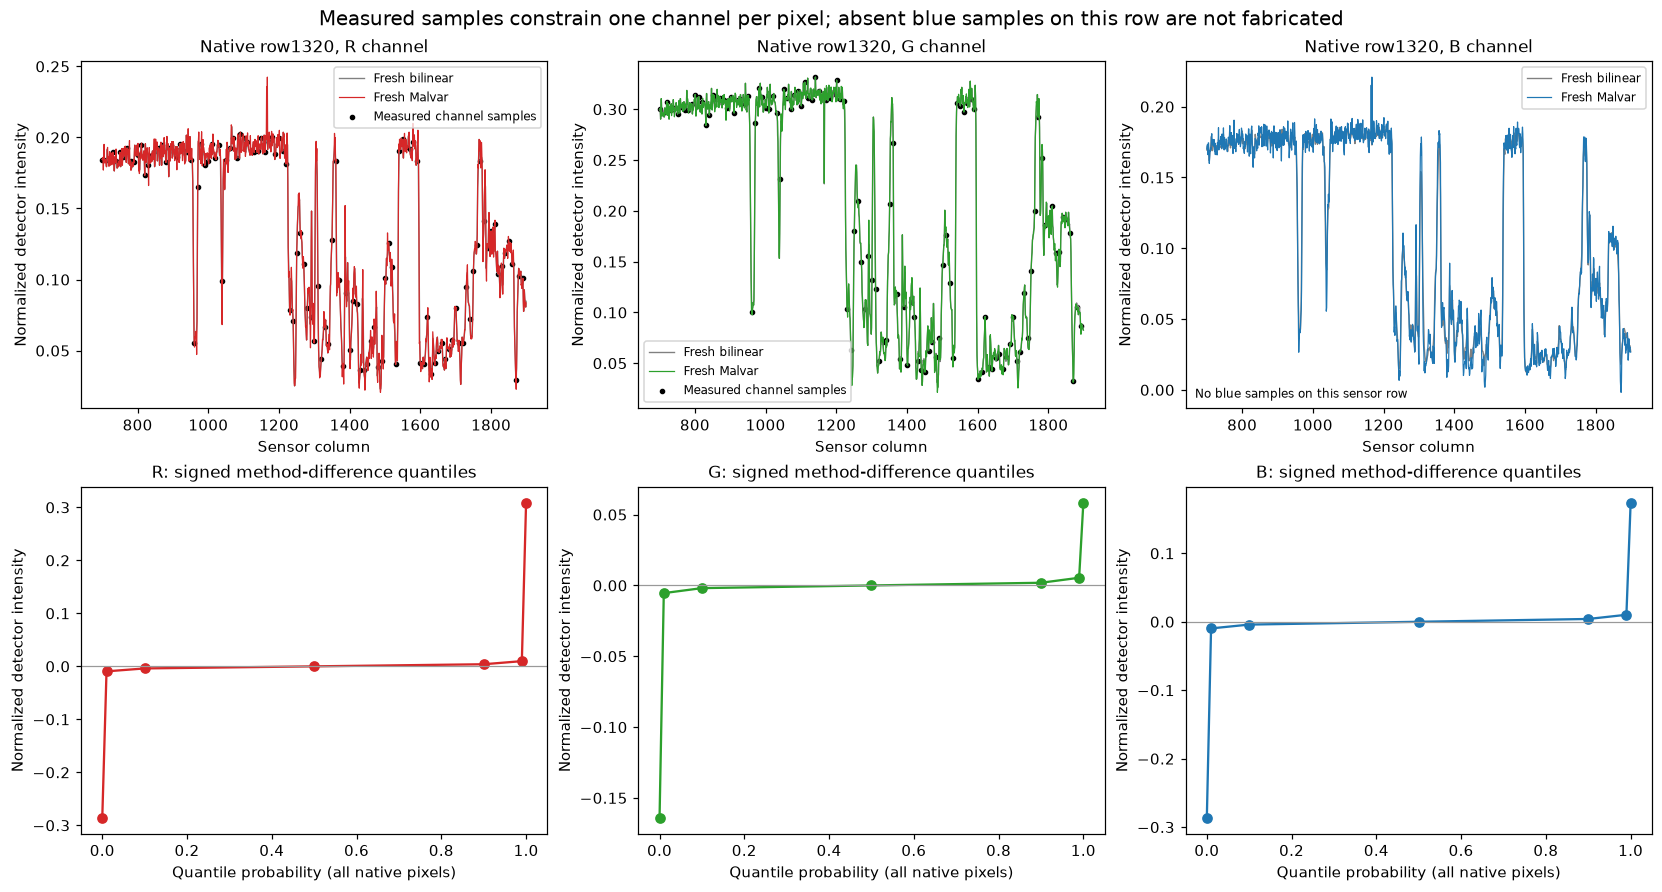

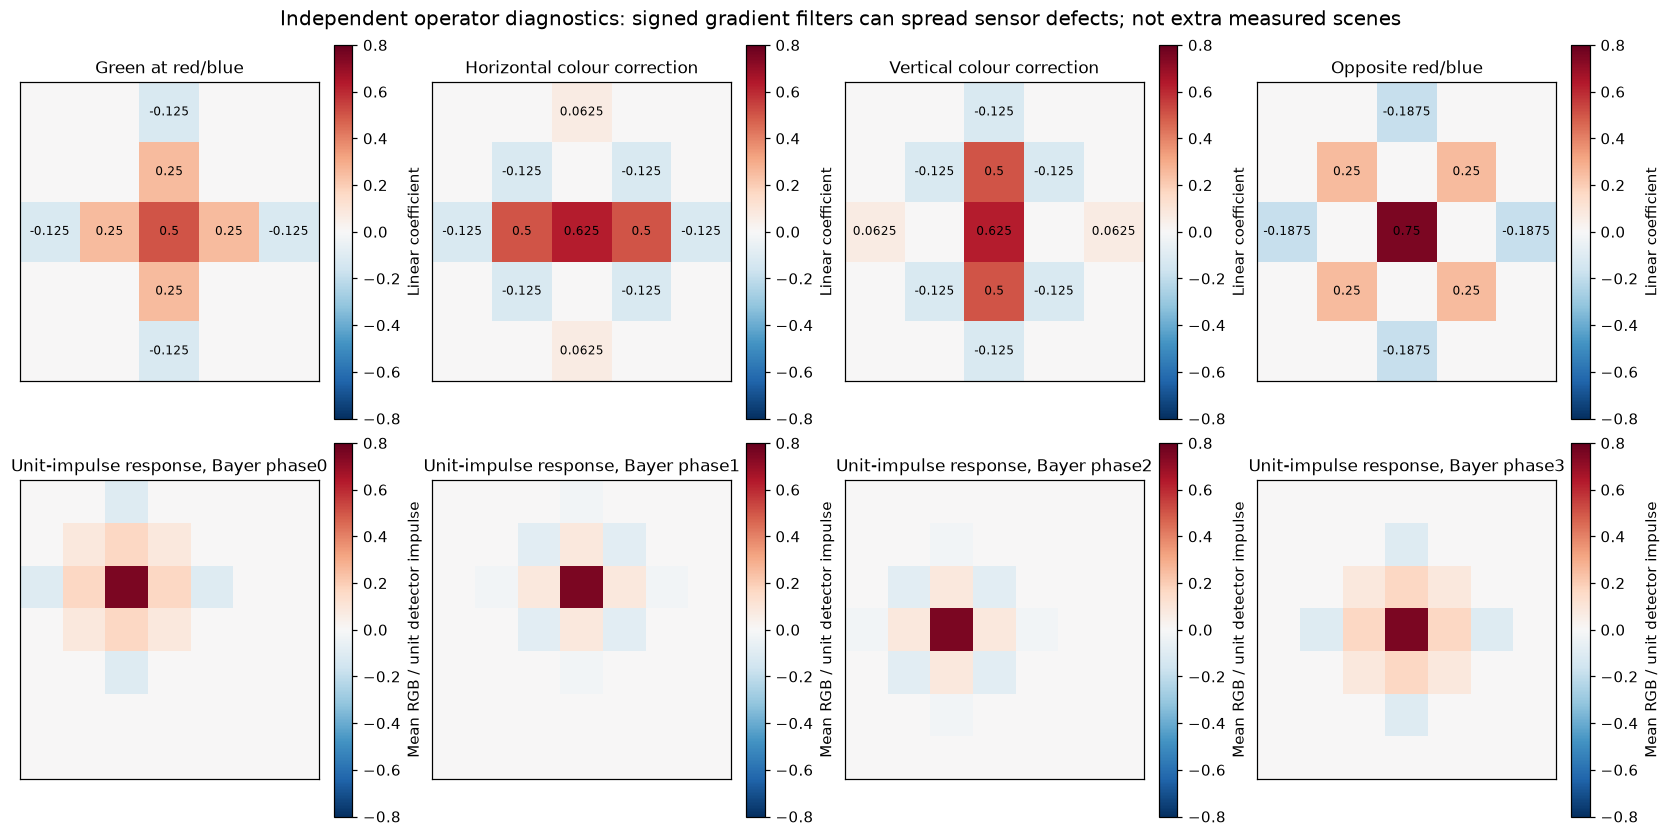

Four groups actively computed; notebook reconstruction/review seconds: 28.592093200000818


In [2]:
figures,numeric=render_figures(mosaic,fresh,bilinear,upstream,wb)
archive=os.environ.get('IMAGING101_FIGURE_DIR')
if archive:
    archive=Path(archive).resolve()
    assert task.resolve() not in archive.parents and archive!=task.resolve()
    archive.mkdir(parents=True,exist_ok=True)
for i,fig in enumerate(figures,1):
    if archive:
        for ext in ['png','svg','pdf']: fig.savefig(archive/f'figure-{i}.{ext}',dpi=220,bbox_inches='tight')
    plt.show()
    plt.close(fig)
if archive:
    np.savez_compressed(archive/'figure_source.npz',**numeric)
    (archive/'experiment_metrics.json').write_text(json.dumps(measurements,indent=2,allow_nan=False),encoding='utf8')
print('Four groups actively computed; notebook reconstruction/review seconds:',time.perf_counter()-start)

## Scientific conclusion

The native-grid local extraction agrees with the independent original implementation and exactly reproduces observed colour samples. This validates the selected method's numerical extraction and acquisition conventions. The unseen two colour components per pixel remain prior-dependent. Neither higher apparent sharpness nor identical sampling error establishes physical accuracy. Real sensor defects and noise remain visible; the signed gradient kernels can spread them, and edge extension is a numerical assumption. No sensor-rendered JPEG or reference reconstruction is relabeled as truth. The full CLI and standalone Judge are separate verified interfaces documented in the validation record.